# One assay, one honest QSAR pilot
**Human dopamine D2 · ChEMBL CHEMBL3855278 · experimental binding pKi, standardized by ChEMBL to Ki.**

This notebook fits a small fixed model, not a data-retrieval demo. The input is one frozen assay, not pooled targets or endpoints. Source-reported pKi, conversion checks, calculated descriptors and predictions remain separate. The old 250-compound model and public explorer are unchanged.

Run beside `pilot.py`, `input_hashes.json`, `predeclared_recipe.json` and `frozen/` from the supplied bundle. **Offline replay:** use the tested environment in `requirements-tested.txt`; no network, EXE, DLL or installation runs in these cells. Fresh Colab is a separate, untested environment: install the listed Python packages there and place the bundle in its working directory before Run all. Nothing is uploaded automatically.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
import pilot
ROOT = Path.cwd()
assert (ROOT / 'input_hashes.json').is_file(), 'Run from the extracted bundle directory.'
pilot.verify_frozen(ROOT)
recipe = json.loads((ROOT / 'predeclared_recipe.json').read_text())
print(recipe['models'], '\nNo tuning; preprocessing sees training data only.')


['training mean DummyRegressor', 'StandardScaler fitted on train + Ridge alpha=1.0'] 
No tuning; preprocessing sees training data only.


## 1. Keep the measurement trail
The frozen cohort ledger retains original and standardized values, relations, units, activity IDs and structure decisions. Source-reported pKi is experimental evidence; ChEMBL standardized Ki (nM) is a representation of that measurement, not a new experiment. Only exact source-reported pKi with a valid matching standardized Ki enters the fit; censored records do not become exact labels. For Ki in nM, **pKi = 9 − log10(Ki)**. The model uses original source-reported pKi, avoiding artificial precision from the back-conversion; round-trip pKi is a separate check that can differ slightly through rounding. Source pKi is not a model prediction. All full-isomeric parent identities with multiple source records are excluded regardless of label agreement; unresolved pairs are not averaged. Repeated records and exclusions remain inspectable in `frozen/`; see its cohort report for exact decisions and protocol-verification limits.


In [2]:
cohort = pd.read_csv(ROOT / 'frozen' / 'eligible_compounds.csv')
display(cohort.head())
print(f'{len(cohort)} eligible compounds; one assay/document only.')


80 eligible compounds; one assay/document only.


,compound_id,molecule_chembl_id,parent_molecule_chembl_id,activity_id,source_activity_ids,assay_chembl_id,target_chembl_id,document_chembl_id,canonical_smiles,source_canonical_smiles,label_origin,pKi,expected_Ki_nM_from_original,standard_Ki_nM,roundtrip_pKi,roundtrip_minus_source_pKi,standard_Ki_nM_minus_original_conversion,conversion_tolerance_nM,parent_smiles,parent_isomeric_smiles,parent_inchikey,parent_nonisomeric_smiles,parent_connectivity_key,scaffold_smiles,structure_changed_from_source,source_records_for_full_identity,decision,exclusion_reasons,original_type,original_value,original_units,original_relation,standard_type,standard_value,standard_units,standard_relation,pchembl_value,potential_duplicate,data_validity_comment,activity_comment,source_activity_url
0,OLWRVVHPJFLNPW-LSNLESRRSA-N,CHEMBL85606,CHEMBL85606,16670133,16670133,CHEMBL3855278,CHEMBL217,CHEMBL3853329,N#Cc1ccc2c(c1)CCN(CC[C@H]1CC[C@H](NC(=O)c3ccnc...,N#Cc1ccc2c(c1)CCN(CC[C@H]1CC[C@H](NC(=O)c3ccnc...,source_reported_pKi,6.31,489.778819,489.78,6.309999,-1.046883e-06,0.001181,0.00501,N#Cc1ccc2c(c1)CCN(CC[C@H]1CC[C@H](NC(=O)c3ccnc...,N#Cc1ccc2c(c1)CCN(CC[C@H]1CC[C@H](NC(=O)c3ccnc...,OLWRVVHPJFLNPW-LSNLESRRSA-N,N#Cc1ccc2c(c1)CCN(CCC1CCC(NC(=O)c3ccnc4ccccc34...,12fb7de3da853f4c88ed5c3b3893f79b17e17e82d3ac4d...,O=C(NC1CCC(CCN2CCc3ccccc3C2)CC1)c1ccnc2ccccc12,False,1,include,NaN,pKi,6.31,NaN,=,Ki,489.78,nM,=,6.31,0,NaN,NaN,https://www.ebi.ac.uk/chembl/api/data/activity...
1,AAPXNHMQKBDDJN-XMSQKQJNSA-N,CHEMBL3901211,CHEMBL3901211,16670136,16670136,CHEMBL3855278,CHEMBL217,CHEMBL3853329,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@@H]3c3ccccc3...,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@@H]3c3ccccc3...,source_reported_pKi,6.15,707.945784,707.95,6.149997,-2.586092e-06,0.004216,0.00501,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@@H]3c3ccccc3...,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@@H]3c3ccccc3...,AAPXNHMQKBDDJN-XMSQKQJNSA-N,Cc1ncoc1-c1nnc(SCCCN2CCC3(CC3c3ccccc3)C2)n1C,5f5097a99ca905252039130a837b04ee6e5d355221accf...,c1ccc(C2CC23CCN(CCCSc2nnc(-c4cnco4)[nH]2)C3)cc1,False,1,include,NaN,pKi,6.15,NaN,=,Ki,707.95,nM,=,6.15,0,NaN,NaN,https://www.ebi.ac.uk/chembl/api/data/activity...
2,AAPXNHMQKBDDJN-PGRDOPGGSA-N,CHEMBL3983937,CHEMBL3983937,16670139,16670139,CHEMBL3855278,CHEMBL217,CHEMBL3853329,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@H]3c3ccccc3)...,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@H]3c3ccccc3)...,source_reported_pKi,6.10,794.328235,794.33,6.099999,-9.651535e-07,0.001765,0.00501,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@H]3c3ccccc3)...,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@H]3c3ccccc3)...,AAPXNHMQKBDDJN-PGRDOPGGSA-N,Cc1ncoc1-c1nnc(SCCCN2CCC3(CC3c3ccccc3)C2)n1C,5f5097a99ca905252039130a837b04ee6e5d355221accf...,c1ccc(C2CC23CCN(CCCSc2nnc(-c4cnco4)[nH]2)C3)cc1,False,1,include,NaN,pKi,6.10,NaN,=,Ki,794.33,nM,=,6.10,0,NaN,NaN,https://www.ebi.ac.uk/chembl/api/data/activity...
3,MNAFRWGRFIBAQX-XMSQKQJNSA-N,CHEMBL3944642,CHEMBL3944642,16670142,16670142,CHEMBL3855278,CHEMBL217,CHEMBL3853329,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@@H]3c3ccc(C(...,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@@H]3c3ccc(C(...,source_reported_pKi,6.20,630.957344,630.96,6.199998,-1.827818e-06,0.002656,0.00501,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@@H]3c3ccc(C(...,Cc1ncoc1-c1nnc(SCCCN2CC[C@@]3(C[C@@H]3c3ccc(C(...,MNAFRWGRFIBAQX-XMSQKQJNSA-N,Cc1ncoc1-c1nnc(SCCCN2CCC3(CC3c3ccc(C(F)(F)F)cc...,e3a2c9462c470a8faba1f80f0df7030c9cff4d7388916c...,c1ccc(C2CC23CCN(CCCSc2nnc(-c4cnco4)[nH]2)C3)cc1,False,1,include,NaN,pKi,6.20,NaN,=,Ki,630.96,nM,=,6.20,0,NaN,NaN,https://www.ebi.ac.uk/chembl/api/data/activity...
4,KLQDZSYTMPJBBU-DYESRHJHSA-N,CHEMBL3953365,CHEMBL3953365,16670148,16670148,CHEMBL3855278,CHEMBL217,CHEMBL3853329,Cc1ncoc1-c1nnc(SCCN2CC[C@@]3(C[C@@H]3c3ccc(C(F...,Cc1ncoc1-c1nnc(SCCN2CC[C@@]3(C[C@@H]3c3ccc(C(F...,source_reported_pKi,6.10,794.328235,794.33,6.099999,-9.651535e-07,0.001765,0.00501,Cc1ncoc1-c1nnc(SCCN2CC[C@@]3(C[C@@H]3c3ccc(C(F...,Cc1ncoc1-c1nnc(SCCN2CC[C@@]3(C[C@@H]3c3ccc(C(F...,KLQDZSYTMPJBBU-DYESRHJHSA-N,Cc1ncoc1-c1nnc(SCCN2CCC3(CC3c3ccc(C(F)(F)F)cc3...,bbd50de4d018

## 2. Freeze chemistry and split before fitting
Five explicit descriptors use Pat Walters’ `useful_rdkit_utils.RDKitDescriptors`: molecular weight, calculated LogP, TPSA, H-bond donors and acceptors. Descriptors use the explicitly curated parent SMILES; source structures and the parent-selection decision remain in the ledger. No extra neutralization or tautomerization is performed by the modeling step.

The predeclared algorithm groups nonchiral Murcko scaffolds **and** parent/connectivity identities, orders groups by a seeded SHA-256 hash, then allocates whole groups toward 20% holdout while retaining at least 10 training and 5 test compounds. Only if group sizes make that impossible, use parent/connectivity groups and disclose congeneric interpolation limits. No activity value chooses the split. Exact implementation is frozen in `pilot.py`.


In [3]:
dataset, molecules, split_info = pilot.prepare(ROOT)
display(pd.Series(split_info, name='Pre-fit split'))
display(dataset.groupby('split')[pilot.FEATURES].agg(['count', 'mean']))


method                                          scaffold_and_parent_grouped
groups                                                                   32
group_sizes               [18, 14, 7, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2...
target_test_count                                                        16
achieved_test_fraction                                               0.2875
seed                                                         assay-pilot-v1
Name: Pre-fit split, dtype: object

MolWt             MolLogP  ...           NumHAcceptors          
      count        mean   count  ...      mean         count      mean
split                            ...                                  
test     23  474.161261      23  ...  0.086957            23  5.869565
train    57  488.551105      57  ...  0.192982            57  5.438596

[2 rows x 10 columns]

## 3. Fit once; compare against the training mean
`StandardScaler → Ridge(alpha=1)` is fixed in advance. No feature selection, hyperparameter search or holdout-driven changes. The baseline always predicts the **training** mean. Both models are scored on exactly the same untouched holdout. There is no final all-data refit.


In [4]:
report = pilot.run(ROOT)
display(pd.DataFrame(report['holdout_metrics']).T.round(4))
print(f"Train: {report['train_n']}; test: {report['test_n']}; total: {report['cohort_n']}")


Train: 57; test: 23; total: 80


,test_n,MAE,RMSE,R2
training_mean,23.0,0.3757,0.4969,-0.0768
ridge_alpha_1,23.0,0.3699,0.4912,-0.0524


**Observed result:** 80 compounds → 57 train and 23 holdout. Whole-group allocation produced 28.75% holdout rather than exactly 20%; the holdout covers only **6 scaffolds**. Ridge MAE/RMSE = **0.370/0.491 pKi**, versus **0.376/0.497** for the training mean. R² is negative for both (−0.052 and −0.077). The small numerical advantage does **not** establish useful predictive skill. Predictions stay near the training mean and miss the observed potency range. No alternate split/model was tried to improve these results.


## 4. Inspect errors, not just a score
MAE/RMSE are in pKi units; lower is better. R² can be negative. A tiny single-assay holdout is not external validation and cannot establish superiority over the unrelated old model. Descriptor-range and nearest-training Morgan similarity are **descriptive warnings**, not calibrated uncertainty or proof of applicability.


,molecule_chembl_id,pKi,predicted_pKi_ridge,predicted_pKi_train_mean,residual_observed_minus_predicted,outside_training_descriptor_range,max_train_morgan_similarity
1,CHEMBL3901211,6.15,6.136685,6.149474,0.013315,True,0.782609
2,CHEMBL3983937,6.10,6.136685,6.149474,-0.036685,True,0.782609
3,CHEMBL3944642,6.20,6.185146,6.149474,0.014854,False,0.969231
7,CHEMBL3975989,7.20,6.185146,6.149474,1.014854,False,0.733333
8,CHEMBL3905196,5.80,6.185146,6.149474,-0.385146,False,0.733333
9,CHEMBL3912029,6.10,6.130594,6.149474,-0.030594,False,0.811594
10,CHEMBL3963783,6.62,6.130594,6.149474,0.489406,False,0.811594
11,CHEMBL3945775,6.02,6.124502,6.149474,-0.104502,False,0.697368
12,CHEMBL3926847,6.59,6.124502,6.149474,0.465498,False,0.697368
13,CHEMBL3901587,6.01,6.179055,6.149474,-0.169055,False,0.773333


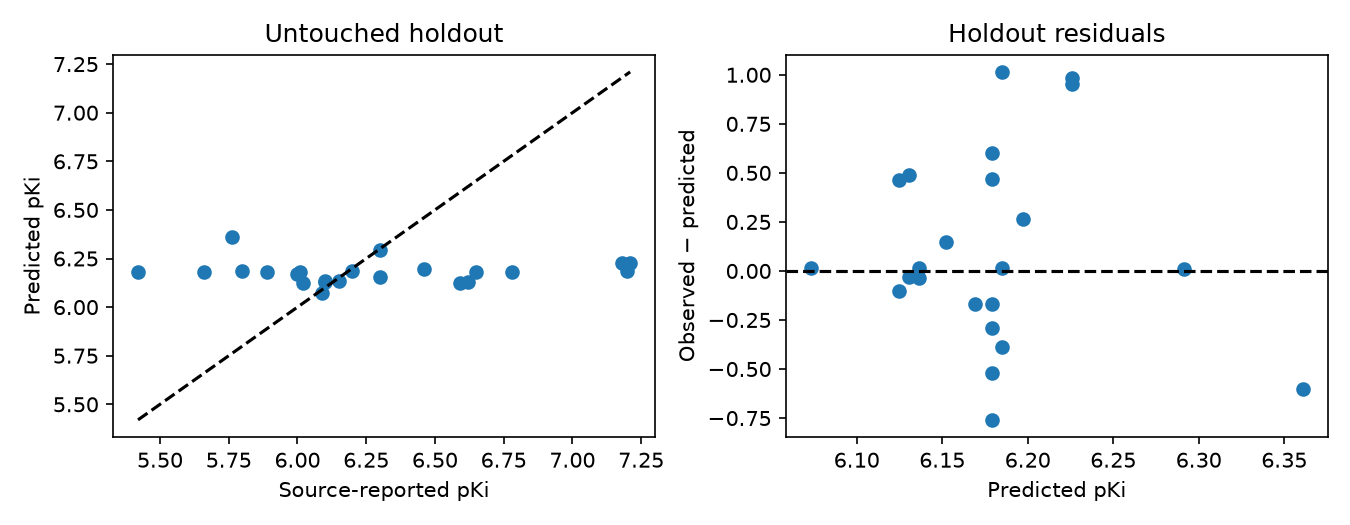

In [5]:
predictions = pd.read_csv(ROOT / 'results' / 'predictions.csv')
heldout = predictions.query("split == 'test'")
display(heldout[['molecule_chembl_id', 'pKi', 'predicted_pKi_ridge',
    'predicted_pKi_train_mean', 'residual_observed_minus_predicted',
    'outside_training_descriptor_range', 'max_train_morgan_similarity']])
display(Image(filename=str(ROOT / 'results' / 'holdout.png')))


## 5. Reuse the result carefully
`results/` contains the model dataset, split identities, predictions/residuals, metrics, plot and fitted model. `model_parameters.json` is the transparent scaler/coefficient export; `model.joblib` is a Python serialization—load only your own trusted copy. The hash gate verifies input bytes, not scientific truth.

The measured cohort, curation ledger and source provenance travel with the bundle. This is a reproducible exploratory single-assay pilot: its value is an honest baseline comparison, even when Ridge loses. New-assay validation, a larger independent test set and chemical-context review are needed before practical prediction claims.

**Attribution:** descriptor API from [Pat Walters, Useful RDKit Utils](https://github.com/PatWalters/useful_rdkit_utils/tree/1057ec09a6d55768ecbfa0bfe4f0d3ef3f20163f), reviewed version 2.0.1. Workflow code is newly written; no tutorial benchmark is claimed reproduced. Source data: ChEMBL, assay CHEMBL3855278, document CHEMBL3853329; provenance and licensing notes are retained in the frozen bundle.


In [6]:
for limitation in report['limitations']:
    print('•', limitation)
print('Exports:', ', '.join(p.name for p in sorted((ROOT / 'results').iterdir())))


• Single assay/document; no external validation.
• Very small holdout: metrics are uncertain; no model selection or tuning was performed.
• Scaffold grouping does not guarantee unrelated chemistry; nearest training similarity is descriptive.
• Descriptors and predictions are calculated; only source Ki/pKi observations are experimental evidence.
• No claim of improvement over the separate frozen 250-compound model.
Exports: holdout.png, model.joblib, model_dataset.csv, model_parameters.json, predictions.csv, report.json, split_manifest.csv


## Source-provenance check after the first fit

The first model was fitted after the complete cohort was handed off as ready. A later source check identified a possible literature comparator, named GSK598809A in the manuscript, so final release was paused. The registered GSK598809 identity (PubChem CID 11784937) was checked against all 107 source structures: no exact full-identity or stereo-ignored parent-graph match was found. Independent audit confirmed that absence. No exclusion, split change, parameter change or corrective refit was justified or performed.

The suffix “A” and source figure were not visually confirmed, and complete source-table-to-record mapping remains unresolved. This is a **database-attributed, single-assay experimental-label pilot**, not independently verified original laboratory measurements. The original 80-compound cohort and first-fit results remain unchanged. Machine-readable identity checks and source response bytes accompany this note.
